In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.datasets import cifar100
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.regularizers import l2

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [4]:

(X_train, y_train), (X_test, y_test) = cifar100.load_data()

print("Training images shape:", X_train.shape)
print("Training labels shape:", y_train.shape)
print("Testing images shape:", X_test.shape)
print("Testing labels shape:", y_test.shape)


Training images shape: (50000, 32, 32, 3)
Training labels shape: (50000, 1)
Testing images shape: (10000, 32, 32, 3)
Testing labels shape: (10000, 1)


In [5]:

print("Number of training images:", len(X_train))
print("Number of testing images:", len(X_test))

print("Image height:", X_train.shape[1])
print("Image width:", X_train.shape[2])
print("Number of colour channels:", X_train.shape[3])

print("Number of unique classes:", len(np.unique(y_train)))
print("Pixel value range:", X_train.min(), "to", X_train.max())


Number of training images: 50000
Number of testing images: 10000
Image height: 32
Image width: 32
Number of colour channels: 3
Number of unique classes: 100
Pixel value range: 0 to 255


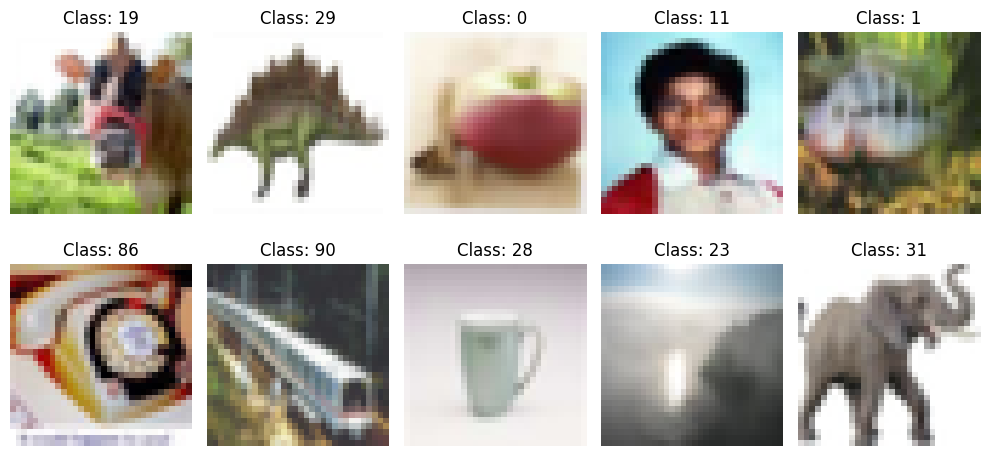

In [6]:

plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i])
    plt.title(f"Class: {y_train[i][0]}")
    plt.axis('off')

plt.tight_layout()
plt.show()


In [7]:

X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

print("Training image range:", X_train.min(), "to", X_train.max())
print("Testing image range:", X_test.min(), "to", X_test.max())


Training image range: 0.0 to 1.0
Testing image range: 0.0 to 1.0


In [8]:

from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train,
    test_size=0.1,
    random_state=42,
    stratify=y_train
)

print("Training data shape:", X_train.shape)
print("Validation data shape:", X_val.shape)
print("Training labels shape:", y_train.shape)
print("Validation labels shape:", y_val.shape)


Training data shape: (45000, 32, 32, 3)
Validation data shape: (5000, 32, 32, 3)
Training labels shape: (45000, 1)
Validation labels shape: (5000, 1)


In [9]:

model = Sequential([
    Conv2D(32, (3, 3), activation='relu',
           kernel_initializer='he_normal',
           kernel_regularizer=l2(0.001),
           padding='same', input_shape=(32, 32, 3)),
    BatchNormalization(),
    MaxPooling2D((2, 2)),
    Dropout(0.25),

    Conv2D(64, (3, 3), activation='relu',
           kernel_initializer='he_normal',
           kernel_regularizer=l2(0.001),
           padding='same'),
    BatchNormalization(),
    MaxPooling2D((2, 2)),
    Dropout(0.25),

    Conv2D(128, (3, 3), activation='relu',
           kernel_initializer='he_normal',
           kernel_regularizer=l2(0.001),
           padding='same'),
    BatchNormalization(),
    MaxPooling2D((2, 2)),
    Dropout(0.25),

    Flatten(),
    Dense(128, activation='relu',
          kernel_initializer='he_normal',
          kernel_regularizer=l2(0.001)),
    BatchNormalization(),
    Dropout(0.5),

    Dense(100, activation='softmax')
])

model.summary()


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 100)            │        12,900 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 369,828 (1.41 MB)

 Trainable params: 369,124 (1.41 MB)

 Non-trainable params: 704 (2.75 KB)

In [10]:

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)


In [11]:

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

model_checkpoint = ModelCheckpoint(
    'best_custom_cnn.keras',
    monitor='val_loss',
    save_best_only=True
)


In [12]:

history = model.fit(
    X_train, y_train,
    epochs=15,
    batch_size=64,
    validation_data=(X_val, y_val),
    callbacks=[early_stopping, model_checkpoint]
)


Epoch 1/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 33s 22ms/step - accuracy: 0.0951 - loss: 4.7573 - val_accuracy: 0.1544 - val_loss: 4.1995
Epoch 2/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.1870 - loss: 3.9315 - val_accuracy: 0.2488 - val_loss: 3.5596
Epoch 3/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.2436 - loss: 3.5396 - val_accuracy: 0.2768 - val_loss: 3.3398
Epoch 4/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.2814 - loss: 3.3104 - val_accuracy: 0.3050 - val_loss: 3.1986
Epoch 5/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.3063 - loss: 3.1719 - val_accuracy: 0.3468 - val_loss: 3.0298
Epoch 6/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.3230 - loss: 3.0958 - val_accuracy: 0.2586 - val_loss: 3.5776
Epoch 7/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.3392 - loss: 3.0310 - val_accuracy: 0.3728 - val_loss: 2.8773
Epoch 8/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.3506 - loss: 3.0051 - val_accuracy: 

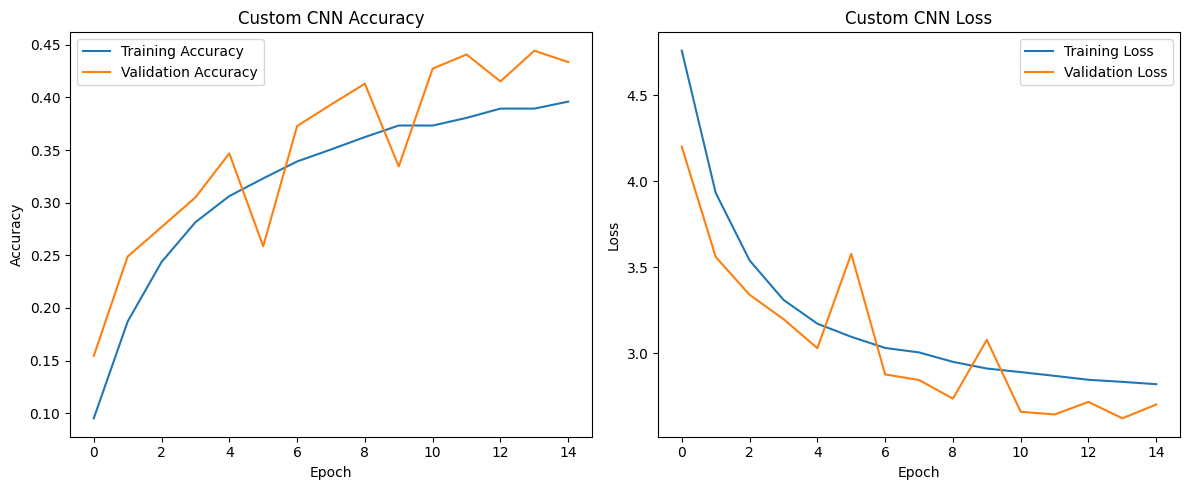

In [13]:

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Custom CNN Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Custom CNN Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()


In [14]:
test_loss, test_accuracy = model.evaluate(X_test, y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.4518 - loss: 2.5939
Test Loss: 2.593925714492798
Test Accuracy: 0.45179998874664307


In [15]:
from sklearn.metrics import precision_score, recall_score, f1_score
import numpy as np

y_pred_probs = model.predict(X_test)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = y_test.reshape(-1)

precision = precision_score(y_true, y_pred, average='macro', zero_division=0)
recall = recall_score(y_true, y_pred, average='macro', zero_division=0)
f1 = f1_score(y_true, y_pred, average='macro', zero_division=0)

print("Precision:", precision)
print("Recall:", recall)
print("F1-Score:", f1)

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step
Precision: 0.4755313156048288
Recall: 0.4517999999999999
F1-Score: 0.4447133246011281


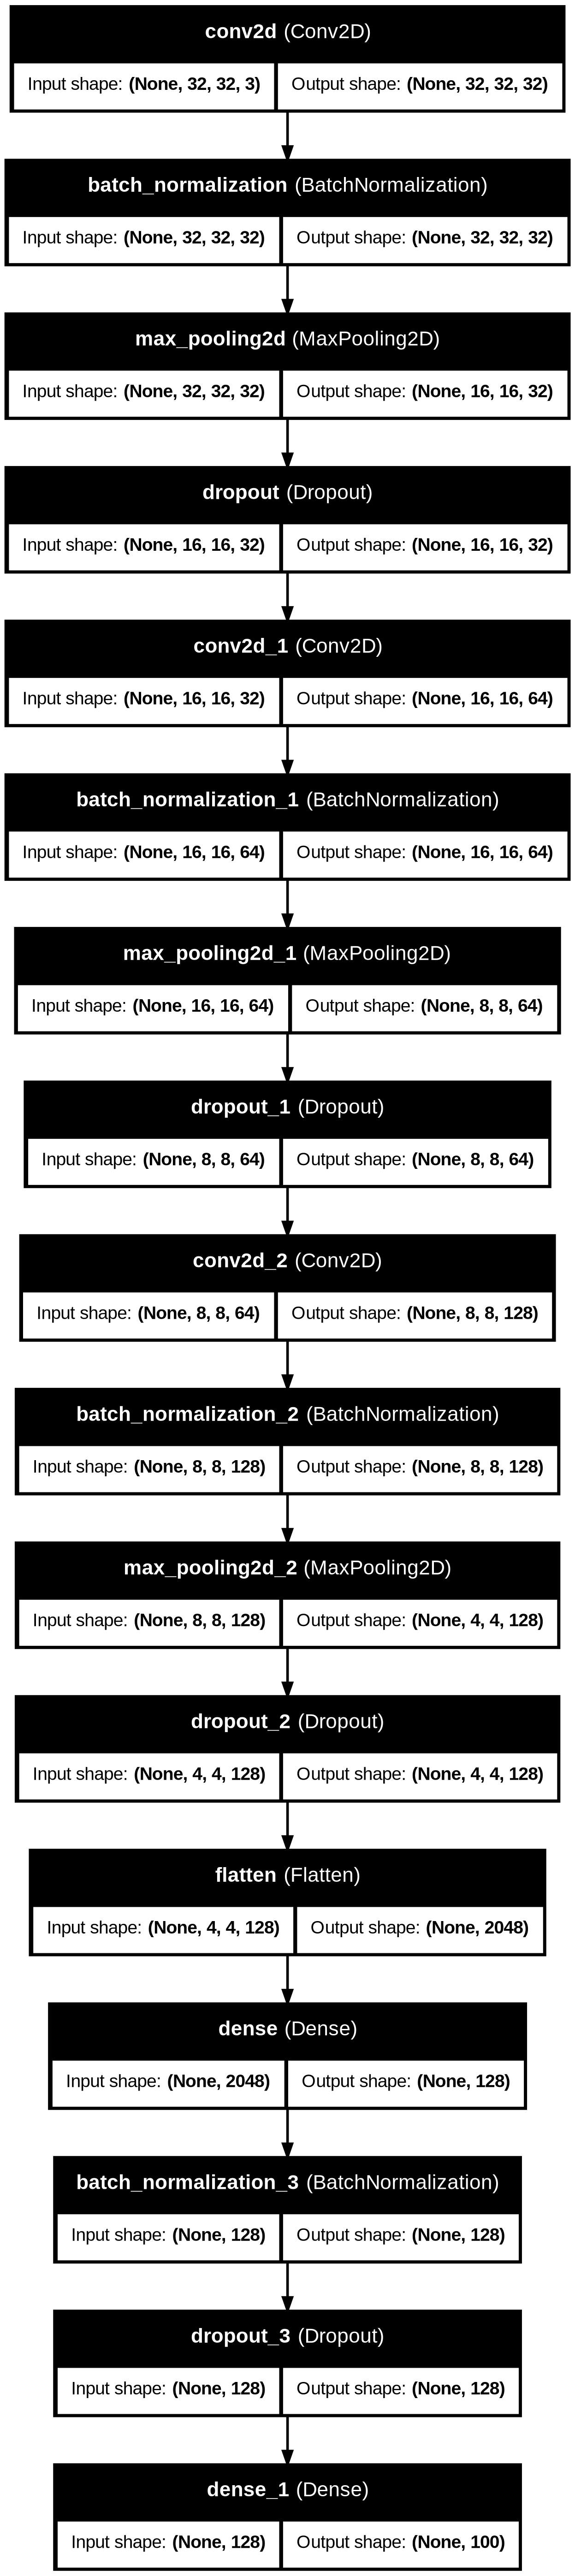

In [16]:
from tensorflow.keras.utils import plot_model

plot_model(
    model,
    to_file='custom_cnn_architecture.png',
    show_shapes=True,
    show_layer_names=True
)

In [17]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 100)            │        12,900 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,108,078 (4.23 MB)

 Trainable params: 369,124 (1.41 MB)

 Non-trainable params: 704 (2.75 KB)

 Optimizer params: 738,250 (2.82 MB)

In [18]:
best_val_accuracy = max(history.history['val_accuracy'])
best_val_loss = min(history.history['val_loss'])

print("Best Validation Accuracy:", best_val_accuracy)
print("Best Validation Loss:", best_val_loss)

Best Validation Accuracy: 0.44440001249313354
Best Validation Loss: 2.6222524642944336


In [19]:
import pandas as pd

custom_cnn_results = pd.DataFrame({
    'Metric': ['Test Loss', 'Test Accuracy', 'Precision', 'Recall', 'F1-Score'],
    'Custom CNN': [
        test_loss,
        test_accuracy,
        precision,
        recall,
        f1
    ]
})

print(custom_cnn_results)

          Metric  Custom CNN
0      Test Loss    2.593926
1  Test Accuracy    0.451800
2      Precision    0.475531
3         Recall    0.451800
4       F1-Score    0.444713


In [31]:
vgg_base_fast = VGG16(
    weights='imagenet',
    include_top=False,
    input_shape=(96, 96, 3)
)

vgg_base_fast.trainable = False

vgg_model_fast = Sequential([
    Input(shape=(32, 32, 3)),
    Resizing(96, 96),
    vgg_base_fast,
    GlobalAveragePooling2D(),
    Dense(256, activation='relu'),
    Dropout(0.5),
    Dense(100, activation='softmax')
])

vgg_model_fast.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resizing_1 (Resizing)           │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 3, 3, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 100)            │        25,700 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,871,716 (56.73 MB)

 Trainable params: 157,028 (613.39 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [32]:
vgg_model_fast.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [33]:
vgg_early_stopping_fast = EarlyStopping(
    monitor='val_loss',
    patience=2,
    restore_best_weights=True
)

vgg_checkpoint_fast = ModelCheckpoint(
    'best_vgg16_fast.keras',
    monitor='val_loss',
    save_best_only=True
)

In [34]:
vgg_history_fast = vgg_model_fast.fit(
    X_train_vgg,
    y_train,
    epochs=5,
    batch_size=64,
    validation_data=(X_val_vgg, y_val),
    callbacks=[
        vgg_early_stopping_fast,
        vgg_checkpoint_fast
    ]
)

Epoch 1/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 58s 76ms/step - accuracy: 0.2342 - loss: 3.6229 - val_accuracy: 0.4622 - val_loss: 2.0804
Epoch 2/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 48s 68ms/step - accuracy: 0.4007 - loss: 2.3326 - val_accuracy: 0.4996 - val_loss: 1.8606
Epoch 3/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 48s 68ms/step - accuracy: 0.4470 - loss: 2.0674 - val_accuracy: 0.5250 - val_loss: 1.7543
Epoch 4/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 48s 68ms/step - accuracy: 0.4805 - loss: 1.9222 - val_accuracy: 0.5414 - val_loss: 1.7125
Epoch 5/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 48s 68ms/step - accuracy: 0.5000 - loss: 1.8349 - val_accuracy: 0.5432 - val_loss: 1.6945


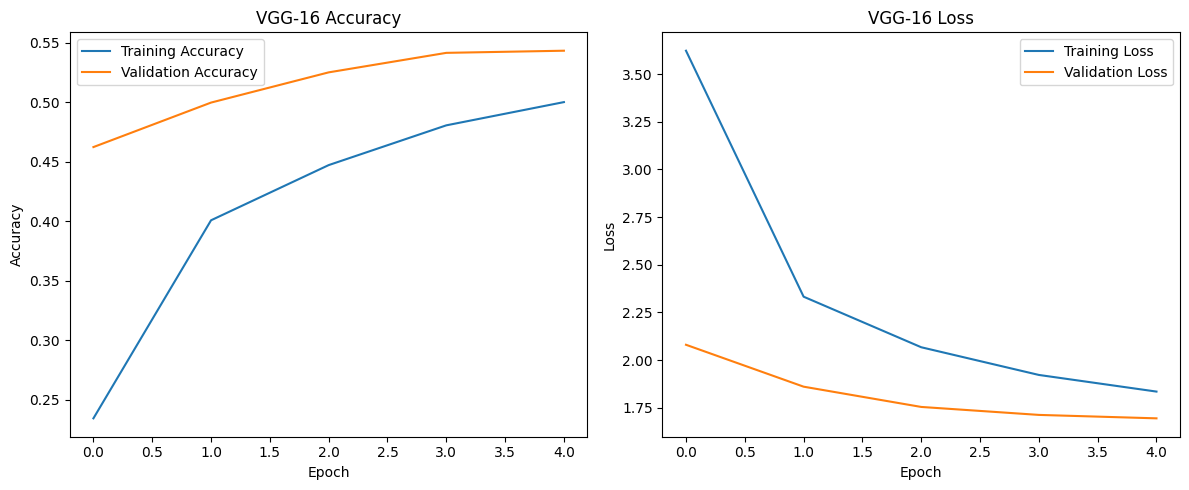

In [35]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(vgg_history_fast.history['accuracy'], label='Training Accuracy')
plt.plot(vgg_history_fast.history['val_accuracy'], label='Validation Accuracy')
plt.title('VGG-16 Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(vgg_history_fast.history['loss'], label='Training Loss')
plt.plot(vgg_history_fast.history['val_loss'], label='Validation Loss')
plt.title('VGG-16 Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [36]:
vgg_test_loss, vgg_test_accuracy = vgg_model_fast.evaluate(
    X_test_vgg, y_test
)

print("VGG-16 Test Loss:", vgg_test_loss)
print("VGG-16 Test Accuracy:", vgg_test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 14s 37ms/step - accuracy: 0.5418 - loss: 1.6981
VGG-16 Test Loss: 1.698058009147644
VGG-16 Test Accuracy: 0.5418000221252441


In [37]:
vgg_pred_probs = vgg_model_fast.predict(X_test_vgg)
vgg_pred = np.argmax(vgg_pred_probs, axis=1)
vgg_true = y_test.reshape(-1)

vgg_precision = precision_score(
    vgg_true, vgg_pred, average='macro', zero_division=0
)

vgg_recall = recall_score(
    vgg_true, vgg_pred, average='macro', zero_division=0
)

vgg_f1 = f1_score(
    vgg_true, vgg_pred, average='macro', zero_division=0
)

print("Precision:", vgg_precision)
print("Recall:", vgg_recall)
print("F1-Score:", vgg_f1)

313/313 ━━━━━━━━━━━━━━━━━━━━ 12s 36ms/step
Precision: 0.5496194505155308
Recall: 0.5418
F1-Score: 0.5367355300829808


In [38]:
vgg_model_fast.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resizing_1 (Resizing)           │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 3, 3, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 100)            │        25,700 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,185,774 (57.93 MB)

 Trainable params: 157,028 (613.39 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

 Optimizer params: 314,058 (1.20 MB)

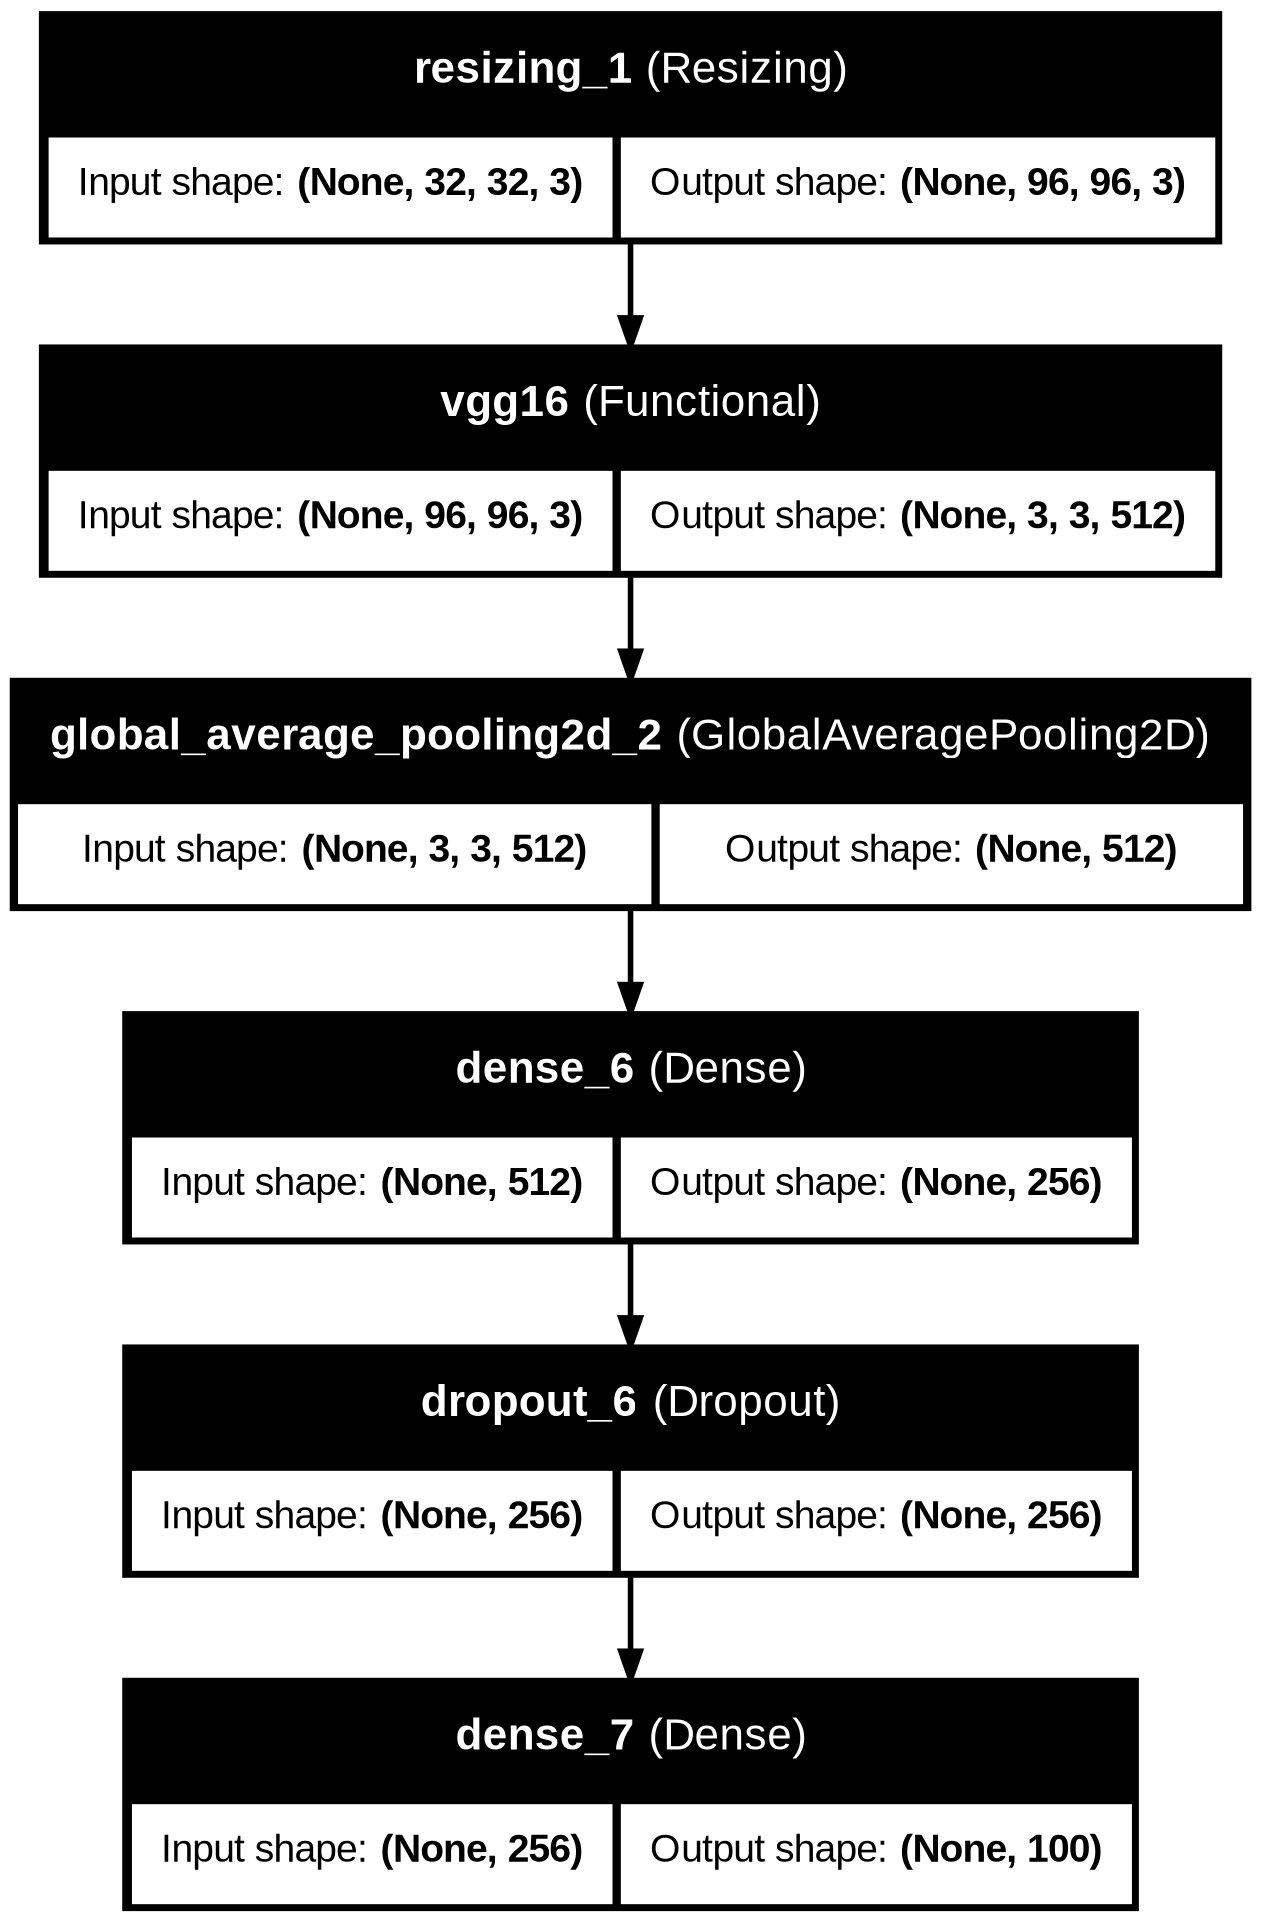

In [39]:
from tensorflow.keras.utils import plot_model

plot_model(
    vgg_model_fast,
    to_file='vgg16_architecture.png',
    show_shapes=True,
    show_layer_names=True
)

In [40]:
comparison = pd.DataFrame({
    'Metric': [
        'Test Loss',
        'Test Accuracy',
        'Precision',
        'Recall',
        'F1-Score'
    ],
    'Custom CNN': [
        test_loss,
        test_accuracy,
        precision,
        recall,
        f1
    ],
    'VGG-16': [
        vgg_test_loss,
        vgg_test_accuracy,
        vgg_precision,
        vgg_recall,
        vgg_f1
    ]
})

print(comparison)

          Metric  Custom CNN    VGG-16
0      Test Loss    2.593926  1.698058
1  Test Accuracy    0.451800  0.541800
2      Precision    0.475531  0.549619
3         Recall    0.451800  0.541800
4       F1-Score    0.444713  0.536736


##Conclusion
The Custom CNN and pretrained VGG-16 models were trained and evaluated on the CIFAR-100 dataset. The Custom CNN achieved a test accuracy of 45.18%, while VGG-16 achieved 54.18%. VGG-16 also obtained better precision, recall, and F1-score, with lower test loss. Therefore, VGG-16 performed better than the Custom CNN in this experiment.